### Estimation of COVID-19 Pandemic

In [1]:
# imporing liabries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Loading data from Github using url
base_url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/" # loading from Internet

infected_dataset_url = base_url + "time_series_covid19_confirmed_global.csv"
recovered_dataset_url = base_url + "time_series_covid19_recovered_global.csv"
deaths_dataset_url = base_url + "time_series_covid19_deaths_global.csv"
countries_dataset_url = base_url + "../UID_ISO_FIPS_LookUp_Table.csv"

In [3]:
# load the data for infected individuals and see how the data looks like:
infected = pd.read_csv(infected_dataset_url)

In [4]:
infected.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


In [5]:
# load both recovered and deaths data
recovered = pd.read_csv(recovered_dataset_url)
deaths = pd.read_csv(deaths_dataset_url)

In [6]:
# viewing the data
infected["Province/State"].value_counts()

Province/State
Australian Capital Territory                    1
New South Wales                                 1
Northern Territory                              1
Queensland                                      1
South Australia                                 1
                                               ..
Jersey                                          1
Montserrat                                      1
Pitcairn Islands                                1
Saint Helena, Ascension and Tristan da Cunha    1
Turks and Caicos Islands                        1
Name: count, Length: 91, dtype: int64

In [7]:
# lets look for more nformation for china as country
infected[infected["Country/Region"]=="China"]

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
59,Anhui,China,31.8257,117.2264,1,9,15,39,60,70,...,2275,2275,2275,2275,2275,2275,2275,2275,2275,2275
60,Beijing,China,40.1824,116.4142,14,22,36,41,68,80,...,40774,40774,40774,40774,40774,40774,40774,40774,40774,40774
61,Chongqing,China,30.0572,107.8740,6,9,27,57,75,110,...,14715,14715,14715,14715,14715,14715,14715,14715,14715,14715
62,Fujian,China,26.0789,117.9874,1,5,10,18,35,59,...,17122,17122,17122,17122,17122,17122,17122,17122,17122,17122
63,Gansu,China,35.7518,104.2861,0,2,2,4,7,14,...,1742,1742,1742,1742,1742,1742,1742,1742,1742,1742
64,Guangdong,China,23.3417,113.4244,26,32,53,78,111,151,...,103248,103248,103248,103248,103248,103248,103248,103248,103248,103248
65,Guangxi,China,23.8298,108.7881,2,5,23,23,36,46,...,13371,13371,13371,13371,13371,13371,13371,13371,13371,13371
66,Guizhou,China,26.8154,106.8748,1,3,3,4,5,7,...,2534,2534,2534,2534,2534,2534,2534,2534,2534,2534
67,Hainan,China,19.1959,109.7453,4,5,8,19,22,33,...,10483,10483,10483,10483,10483,10483,10483,10483,10483,10483
68,Hebei,China,39.5490,116.1306,1,1,2,8,13,18,...,3292,3292,3292,3292,3292,3292,3292,3292,3292,3292


#### Pre-processing the Data

In [8]:
# use groupby to see DataFrames indexed by Country/Region
infected = infected.groupby('Country/Region').sum()
recovered = recovered.groupby('Country/Region').sum()
deaths = deaths.groupby('Country/Region').sum()

In [9]:
infected.head(10)

,Province/State,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,1/28/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
Country/Region,,,,,,,,,,,,,,,,,,,,,
Afghanistan,,33.93911,67.709953,0,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
Albania,,41.15330,20.168300,0,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
Algeria,,28.03390,1.659600,0,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
Andorra,,42.50630,1.521800,0,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
Angola,,-11.20270,17.873900,0,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288
Antarctica,,-71.94990,23.347000,0,0,0,0,0,0,0,...,11,11,11,11,11,11,11,11,11,11
Antigua and Barbuda,,17.06080,-61.796400,0,0,0,0,0,0,0,...,9106,9106,9106,9106,9106,9106,9106,9106,9106,9106
Argentina,,-38.41610,-63.616700,0,0,0,0,0,0,0,...,10044125,10044125,10044125,10044125,10044125,10044125,10044957,10044957,10044957,10044957
Armenia,,40.06910,45.038200,0,0,0,0,0,0,0,...,446819,446819,446819,446819,446819,446819,446819,446819,447308,447308


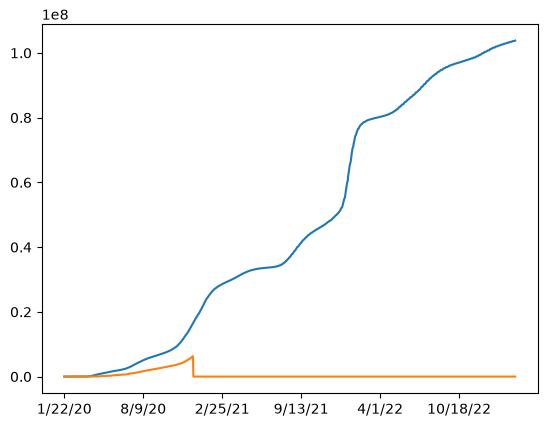

In [10]:
# use .loc: to acess data of specific Country/Region 
# [3:] removes first 3 elements that contains non-date metadata (the Province/State and geolocation columns) 
infected.loc['US'][3:].plot()
recovered.loc['US'][3:].plot()
plt.show()

In [11]:
infected.drop(columns=['Lat','Long','Province/State'],inplace=True)
recovered.drop(columns=['Lat','Long','Province/State'],inplace=True)
deaths.drop(columns=['Lat','Long','Province/State'],inplace=True)

### Investigating the Data

In [12]:
# lets investigate a specific country
def mkframe(Country):
    df = pd.DataFrame({"infected": infected.loc[Country],
                       "recovered": recovered.loc[Country],
                       "deaths": deaths.loc[Country]})
    df.index = pd.to_datetime(df.index)
    return df
df = mkframe("US")
df

C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index)


,infected,recovered,deaths
2020-01-22,1,0,0
2020-01-23,1,0,0
2020-01-24,2,0,0
2020-01-25,2,0,0
2020-01-26,5,0,0
...,...,...,...
2023-03-05,103646975,0,1122134
2023-03-06,103655539,0,1122181
2023-03-07,103690910,0,1122516
2023-03-08,103755771,0,1123246


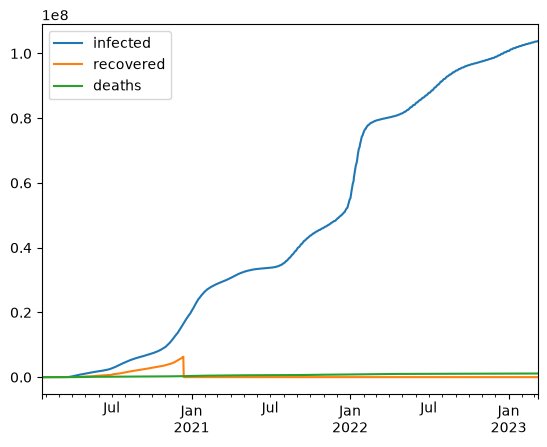

In [13]:
df.plot()
plt.show()

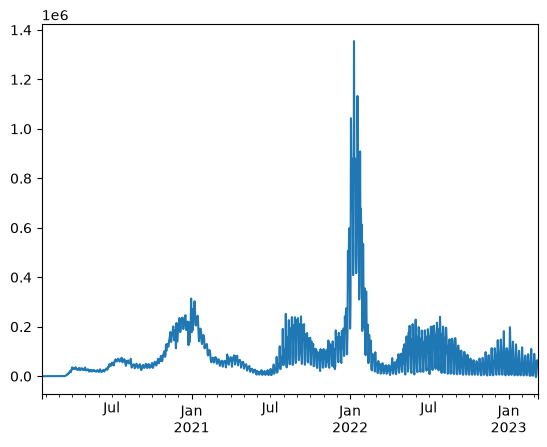

In [14]:
# lets see the speed at which pandemic progresses using diff

df['ninfected'] = df['infected'].diff()
df['ninfected'].plot()
plt.show()

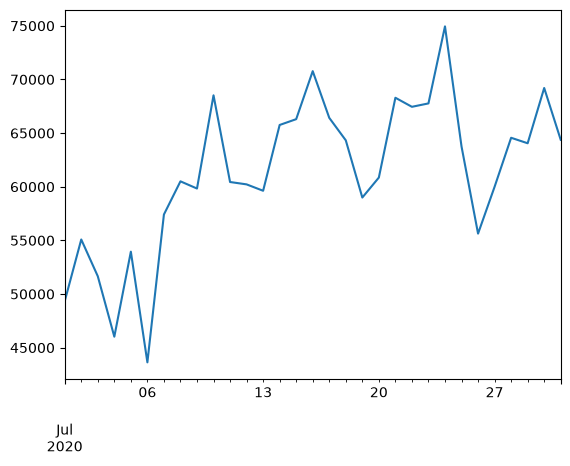

In [15]:
# Let's look closer at one of the months:
df[(df.index.year==2020) & (df.index.month==7)]['ninfected'].plot()
plt.show()

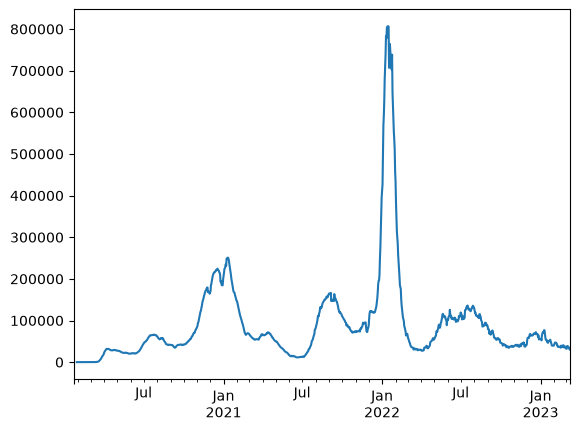

In [16]:
df['ninfav'] = df['ninfected'].rolling(window=7).mean()
df['ninfav'].plot()
plt.show()

In [17]:
# lets compare several countries
countries = pd.read_csv(countries_dataset_url)
countries

,UID,iso2,iso3,code3,FIPS,Admin2,Province_State,Country_Region,Lat,Long_,Combined_Key,Population
0,4,AF,AFG,4.0,NaN,NaN,NaN,Afghanistan,33.939110,67.709953,Afghanistan,38928341.0
1,8,AL,ALB,8.0,NaN,NaN,NaN,Albania,41.153300,20.168300,Albania,2877800.0
2,10,AQ,ATA,10.0,NaN,NaN,NaN,Antarctica,-71.949900,23.347000,Antarctica,NaN
3,12,DZ,DZA,12.0,NaN,NaN,NaN,Algeria,28.033900,1.659600,Algeria,43851043.0
4,20,AD,AND,20.0,NaN,NaN,NaN,Andorra,42.506300,1.521800,Andorra,77265.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4316,84056037,US,USA,840.0,56037.0,Sweetwater,Wyoming,US,41.659439,-108.882788,"Sweetwater, Wyoming, US",42343.0
4317,84056039,US,USA,840.0,56039.0,Teton,Wyoming,US,43.935225,-110.589080,"Teton, Wyoming, US",23464.0
4318,84056041,US,USA,840.0,56041.0,Uinta,Wyoming,US,41.287818,-110.547578,"Uinta, Wyoming, US",20226.0
4319,84056043,US,USA,840.0,56043.0,Washakie,Wyoming,US,43.904516,-107.680187,"Washakie, Wyoming, US",7805.0


In [18]:
countries[(countries['Country_Region']=='US') & countries['Province_State'].isna()]

,UID,iso2,iso3,code3,FIPS,Admin2,Province_State,Country_Region,Lat,Long_,Combined_Key,Population
915,840,US,USA,840.0,NaN,NaN,NaN,US,40.0,-100.0,US,329466283.0


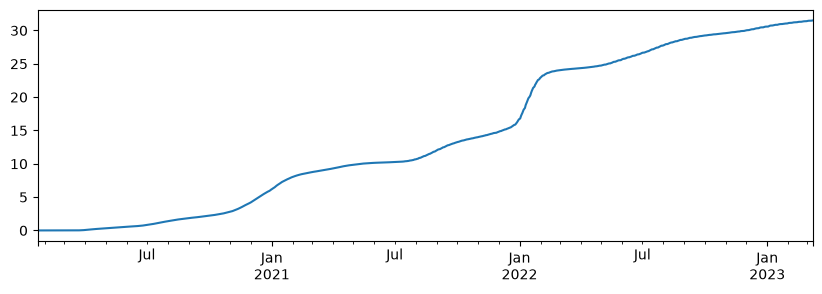

In [19]:
pop = countries[(countries['Country_Region']=='US') & countries['Province_State'].isna()]['Population'].iloc[0]
df['pinfected'] = df['infected']*100 / pop
df['pinfected'].plot(figsize=(10,3))
plt.show()

#### computing Rt for our pandemic

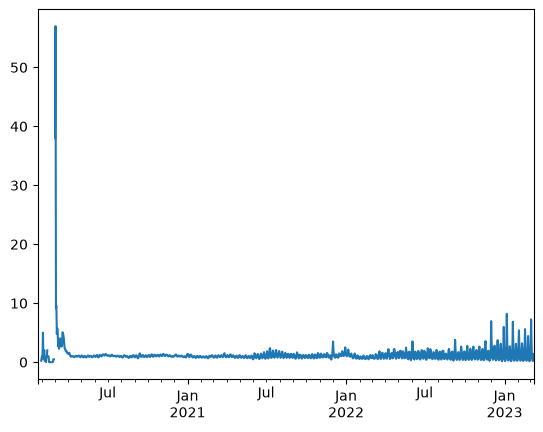

In [20]:
# Let's compute Rt for our pandemic data.
# To do this, we will take a rolling window of 8 ninfected values, and apply the function to compute the ratio above:
df['Rt'] = df['ninfected'].rolling(8).apply(lambda x: x[4:].sum()/x[:4].sum())
df['Rt'].plot()
plt.show()

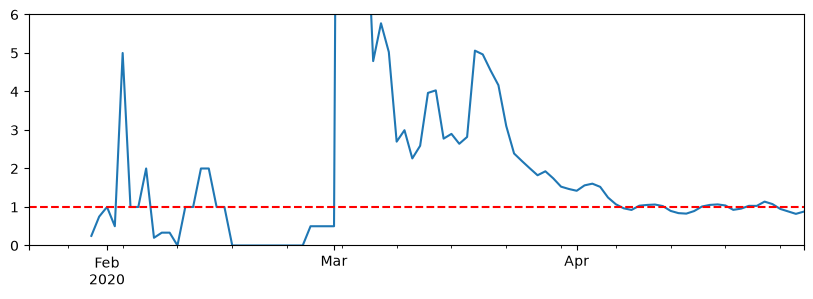

In [23]:
# there are some gaps in the graph this is caused by NaN values in the infected data
# lets fill those values using .replace and .fillna functions
ax = df[df.index < "2020-05-01"]['Rt'].replace([np.inf, -np.inf], np.nan).ffill().plot(figsize=(10, 3))
ax.set_ylim([0, 6])
ax.axhline(1, linestyle='--', color='red')
plt.show()


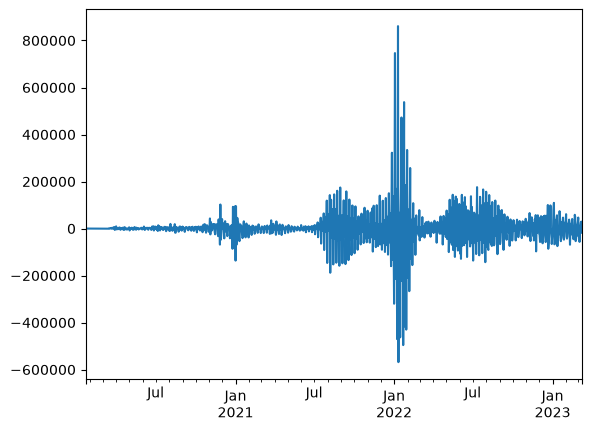

In [24]:
# lets calculate the Derivative or daily difference
df['ninfected'].diff().plot()
plt.show()

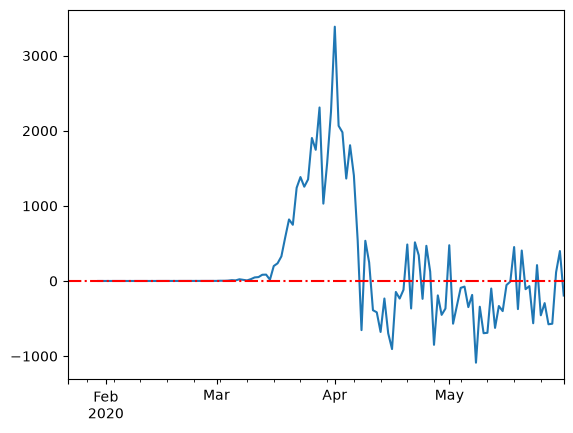

In [25]:
# lets make smooth the curve by running rolling average to get the overall picture
ax=df[df.index<"2020-06-01"]['ninfected'].diff().rolling(7).mean().plot()
ax.axhline(0,linestyle='-.',color='red')
plt.show()

#### ploting Rt graph for several countries for comparison


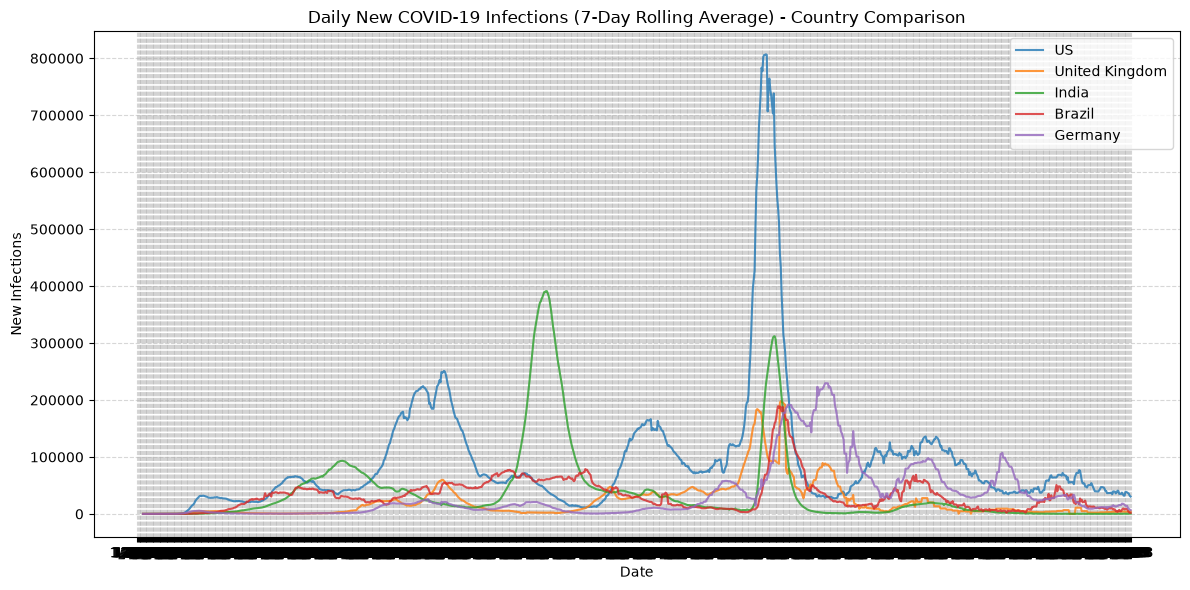

In [28]:
# List of countries you want to compare
countries_to_compare = ["US", "United Kingdom", "India", "Brazil", "Germany"]

plt.figure(figsize=(12, 6))

for country in countries_to_compare:
    # Calculate daily new infections (smoothed or raw diff) for each country
    daily_infected = infected.loc[country][3:].diff()
    
    # Optional: apply a 7-day rolling average to make the graph look cleaner and human-readable
    smoothed = daily_infected.rolling(window=7).mean()
    
    plt.plot(smoothed.index, smoothed, label=country, alpha=0.8)

plt.title("Daily New COVID-19 Infections (7-Day Rolling Average) - Country Comparison")
plt.xlabel("Date")
plt.ylabel("New Infections")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#### Creating Side-by-Side Plots (Subplots)

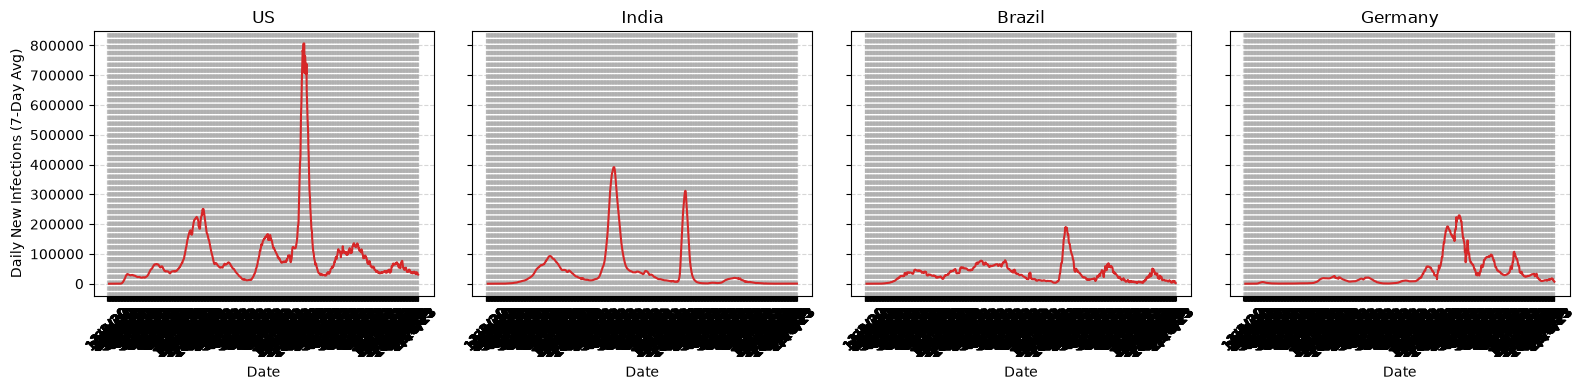

In [29]:
countries_to_compare = ["US", "India", "Brazil", "Germany"]

# Create a figure with 1 row and 4 columns (adjust size as needed)
fig, axes = plt.subplots(nrows=1, ncols=len(countries_to_compare), figsize=(16, 4), sharey=True)

for i, country in enumerate(countries_to_compare):
    daily_infected = infected.loc[country][3:].diff().rolling(window=7).mean()
    
    # Plot on the specific subplot axis
    axes[i].plot(daily_infected.index, daily_infected, color='tab:red')
    axes[i].set_title(country)
    axes[i].set_xlabel("Date")
    axes[i].grid(True, linestyle="--", alpha=0.5)
    
    # Rotate x-axis dates for better readability
    axes[i].tick_params(axis='x', rotation=45)

axes[0].set_ylabel("Daily New Infections (7-Day Avg)")
plt.tight_layout()
plt.show()

#### Correlation between deaths, recoveries and infected


In [30]:
df = mkframe("US")

correlation_matrix = df[['infected', 'recovered', 'deaths']].corr()
print("Cumulative Data Correlation Matrix:")
print(correlation_matrix)

daily_df = df[['infected', 'recovered', 'deaths']].diff().dropna()
daily_correlation = daily_df.corr()
print("\nDaily Changes Correlation Matrix:")
print(daily_correlation)

Cumulative Data Correlation Matrix:
           infected  recovered    deaths
infected   1.000000  -0.405963  0.977123
recovered -0.405963   1.000000 -0.419803
deaths     0.977123  -0.419803  1.000000

Daily Changes Correlation Matrix:
           infected  recovered    deaths
infected   1.000000  -0.024291  0.502961
recovered -0.024291   1.000000 -0.010965
deaths     0.502961  -0.010965  1.000000


C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index)


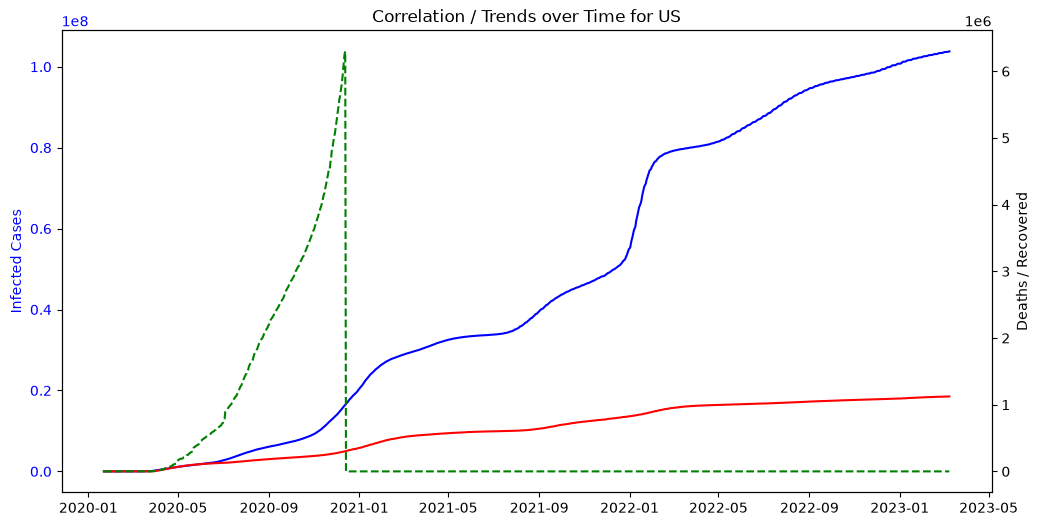

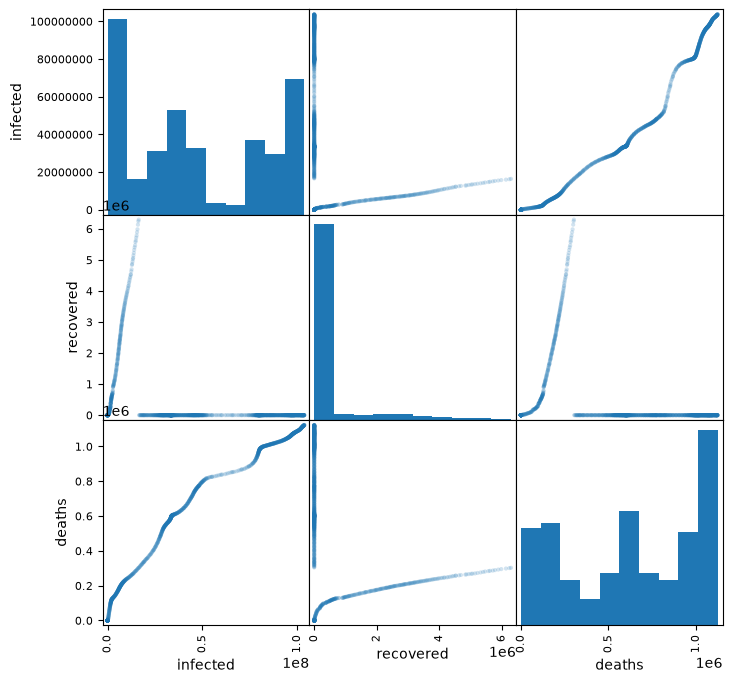

In [31]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(df.index, df['infected'], label='Infected', color='blue')
ax1.set_ylabel('Infected Cases', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(df.index, df['deaths'], label='Deaths', color='red')
ax2.plot(df.index, df['recovered'], label='Recovered', color='green', linestyle='--')
ax2.set_ylabel('Deaths / Recovered', color='black')
ax2.tick_params(axis='y', labelcolor='black')

plt.title('Correlation / Trends over Time for US')
plt.show()

pd.plotting.scatter_matrix(df[['infected', 'recovered', 'deaths']], alpha=0.2, figsize=(8, 8), diagonal='hist')
plt.show()

#### Calculate Daily Numbers (Infections & Deaths)

In [32]:
# Let's pick one country to start with, for example, the US
country_name = 'US'

# Grab the data for this country (dropping extra columns like Latitude/Longitude)
# We assume your dataframe is named 'infected'
df_infected = infected.drop(columns=['Lat', 'Long', 'Province/State'], errors='ignore')
df_deaths = deaths.drop(columns=['Lat', 'Long', 'Province/State'], errors='ignore')

# Extract just this country's row and turn it into a clean list of dates and numbers
cases = df_infected.loc[country_name]
dead = df_deaths.loc[country_name]

# Create a simple new table for our country
my_data = pd.DataFrame({
    'total_cases': cases,
    'total_deaths': dead
})

# Make sure the dates are recognized as actual dates
my_data.index = pd.to_datetime(my_data.index)

# .diff() finds the difference between today and yesterday (gives us daily numbers!)
my_data['daily_cases'] = my_data['total_cases'].diff()
my_data['daily_deaths'] = my_data['total_deaths'].diff()

# Sometimes data corrections cause negative numbers; let's clean those up to 0
my_data['daily_cases'] = my_data['daily_cases'].clip(lower=0)
my_data['daily_deaths'] = my_data['daily_deaths'].clip(lower=0)

# Take a look at the first few days
print(my_data.head())

C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\951840369.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  my_data.index = pd.to_datetime(my_data.index)


            total_cases  total_deaths  daily_cases  daily_deaths
2020-01-22            1             0          NaN           NaN
2020-01-23            1             0          0.0           0.0
2020-01-24            2             0          1.0           0.0
2020-01-25            2             0          0.0           0.0
2020-01-26            5             0          3.0           0.0


In [33]:
# Calculate a 7-day average for daily cases and deaths
my_data['smoothed_cases'] = my_data['daily_cases'].rolling(window=7).mean()
my_data['smoothed_deaths'] = my_data['daily_deaths'].rolling(window=7).mean()

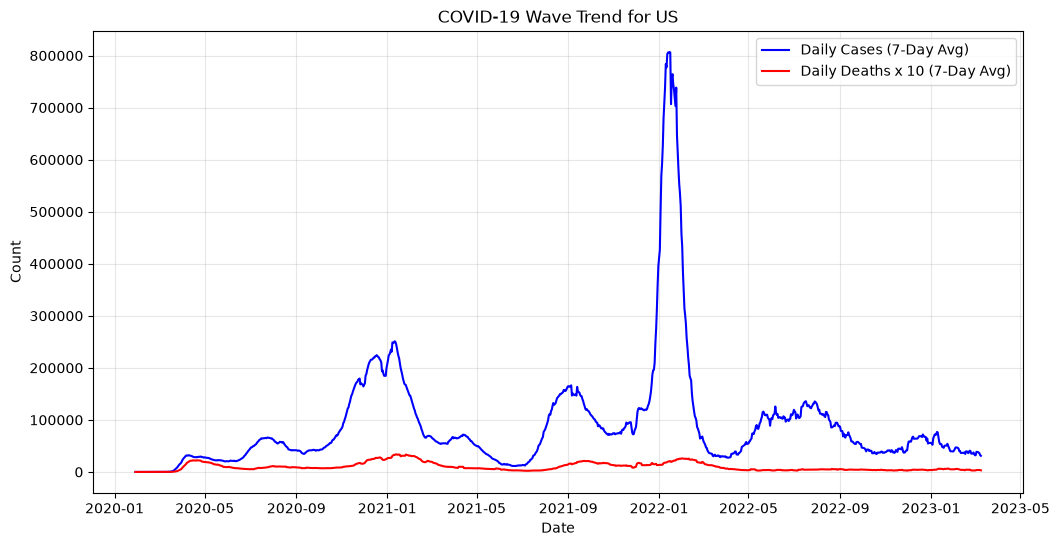

In [34]:
# Set up the chart size
plt.figure(figsize=(12, 6))

# Plot smoothed cases
plt.plot(my_data.index, my_data['smoothed_cases'], label='Daily Cases (7-Day Avg)', color='blue')

# Plot smoothed deaths (we multiply deaths by 10 just so we can see both lines clearly on the same chart scale)
plt.plot(my_data.index, my_data['smoothed_deaths'] * 10, label='Daily Deaths x 10 (7-Day Avg)', color='red')

plt.title(f'COVID-19 Wave Trend for {country_name}')
plt.xlabel('Date')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [35]:
# Let's test shifts from 0 days up to 45 days to see which shift matches best
best_correlation = 0
best_day = 0

for days_delay in range(0, 46):
    # Shift the deaths backward by 'days_delay'
    shifted_deaths = my_data['smoothed_deaths'].shift(-days_delay)
    
    # Measure how well cases match the shifted deaths
    correlation = my_data['smoothed_cases'].corr(shifted_deaths)
    
    if correlation > best_correlation:
        best_correlation = correlation
        best_day = days_delay

print(f"The highest match happens when deaths trail infections by about: {best_day} days!")

The highest match happens when deaths trail infections by about: 18 days!


In [36]:
# Calculate the average and standard deviation of daily cases over the last month
average_cases = my_data['daily_cases'].rolling(window=30).mean()
std_cases = my_data['daily_cases'].rolling(window=30).std()

# If a day is more than 4 standard deviations away from the norm, flag it as an anomaly!
unusual_days = my_data[my_data['daily_cases'] > (average_cases + (4 * std_cases))]

print("Here are some days with unusual reporting spikes:")
print(unusual_days[['daily_cases']].tail(5))

Here are some days with unusual reporting spikes:
            daily_cases
2020-03-05         77.0
2020-03-07        166.0
2020-03-11        365.0
2020-03-16       1467.0
2020-03-19       4494.0


In [37]:
# List of countries to analyze
countries = ["US", "United Kingdom", "Italy", "Brazil", "India"]

country_data = {}

for country in countries:
    # Assuming mkframe(country) builds your time-series DataFrame 
    # with columns: ['infected', 'recovered', 'deaths']
    df = mkframe(country)
    
    # Calculate daily new cases and deaths (first difference)
    # Using a 7-day rolling average to smooth out weekend reporting noise
    df['daily_infected'] = df['infected'].diff().rolling(window=7, min_periods=1).mean()
    df['daily_deaths'] = df['deaths'].diff().rolling(window=7, min_periods=1).mean()
    
    # Drop NaN values resulting from diff()
    country_data[country] = df.dropna(subset=['daily_infected', 'daily_deaths'])

C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2171891664.py:6: UserWarning: Could not infer format, so each element will be parse

In [38]:
def find_optimal_lag(df, max_lag=60):
    """
    Computes cross-correlation between daily infections and daily deaths 
    across different time lags to find the typical delay.
    """
    correlations = {}
    inf = df['daily_infected']
    deaths = df['daily_deaths']
    
    for lag in range(0, max_lag + 1):
        # Shift deaths backward relative to infections
        shifted_deaths = deaths.shift(-lag)
        corr = inf.corr(shifted_deaths)
        correlations[lag] = corr
        
    corr_series = pd.Series(correlations)
    optimal_lag = corr_series.idxmax()
    max_corr = corr_series.max()
    
    return optimal_lag, max_corr, corr_series

# Run lag analysis for each country
lag_results = {}
for country, df in country_data.items():
    opt_lag, max_corr, corr_series = find_optimal_lag(df)
    lag_results[country] = {'optimal_lag': opt_lag, 'max_correlation': max_corr}
    print(f"[{country}] Peak Correlation: {max_corr:.2f} at a lag of {opt_lag} days.")

[US] Peak Correlation: 0.60 at a lag of 18 days.
[United Kingdom] Peak Correlation: 0.14 at a lag of 11 days.
[Italy] Peak Correlation: 0.21 at a lag of 13 days.
[Brazil] Peak Correlation: 0.55 at a lag of 9 days.
[India] Peak Correlation: 0.88 at a lag of 13 days.


In [39]:
anomaly_results = {}

for country, df in country_data.items():
    opt_lag = lag_results[country]['optimal_lag']
    
    # Align deaths with infections using the optimal lag
    analysis_df = pd.DataFrame({
        'infected': df['daily_infected'],
        'deaths_shifted': df['daily_deaths'].shift(-opt_lag)
    }).dropna()
    
    # Calculate the ratio or expected relationship 
    # (using a rolling linear regression proxy or direct ratio)
    rolling_mean_ratio = (analysis_df['deaths_shifted'] / (analysis_df['infected'] + 1)).rolling(window=30).mean()
    rolling_std_ratio = (analysis_df['deaths_shifted'] / (analysis_df['infected'] + 1)).rolling(window=30).std()
    
    # Z-score of the ratio to flag anomalies (e.g., Z > 3 or Z < -3)
    current_ratio = analysis_df['deaths_shifted'] / (analysis_df['infected'] + 1)
    analysis_df['z_score'] = (current_ratio - rolling_mean_ratio) / rolling_std_ratio
    
    # Filter anomalies
    anomalies = analysis_df[abs(analysis_df['z_score']) > 3.0]
    anomaly_results[country] = anomalies
    
    print(f"[{country}] Detected {len(anomalies)} anomalous periods.")

[US] Detected 13 anomalous periods.
[United Kingdom] Detected 12 anomalous periods.
[Italy] Detected 15 anomalous periods.
[Brazil] Detected 20 anomalous periods.
[India] Detected 33 anomalous periods.


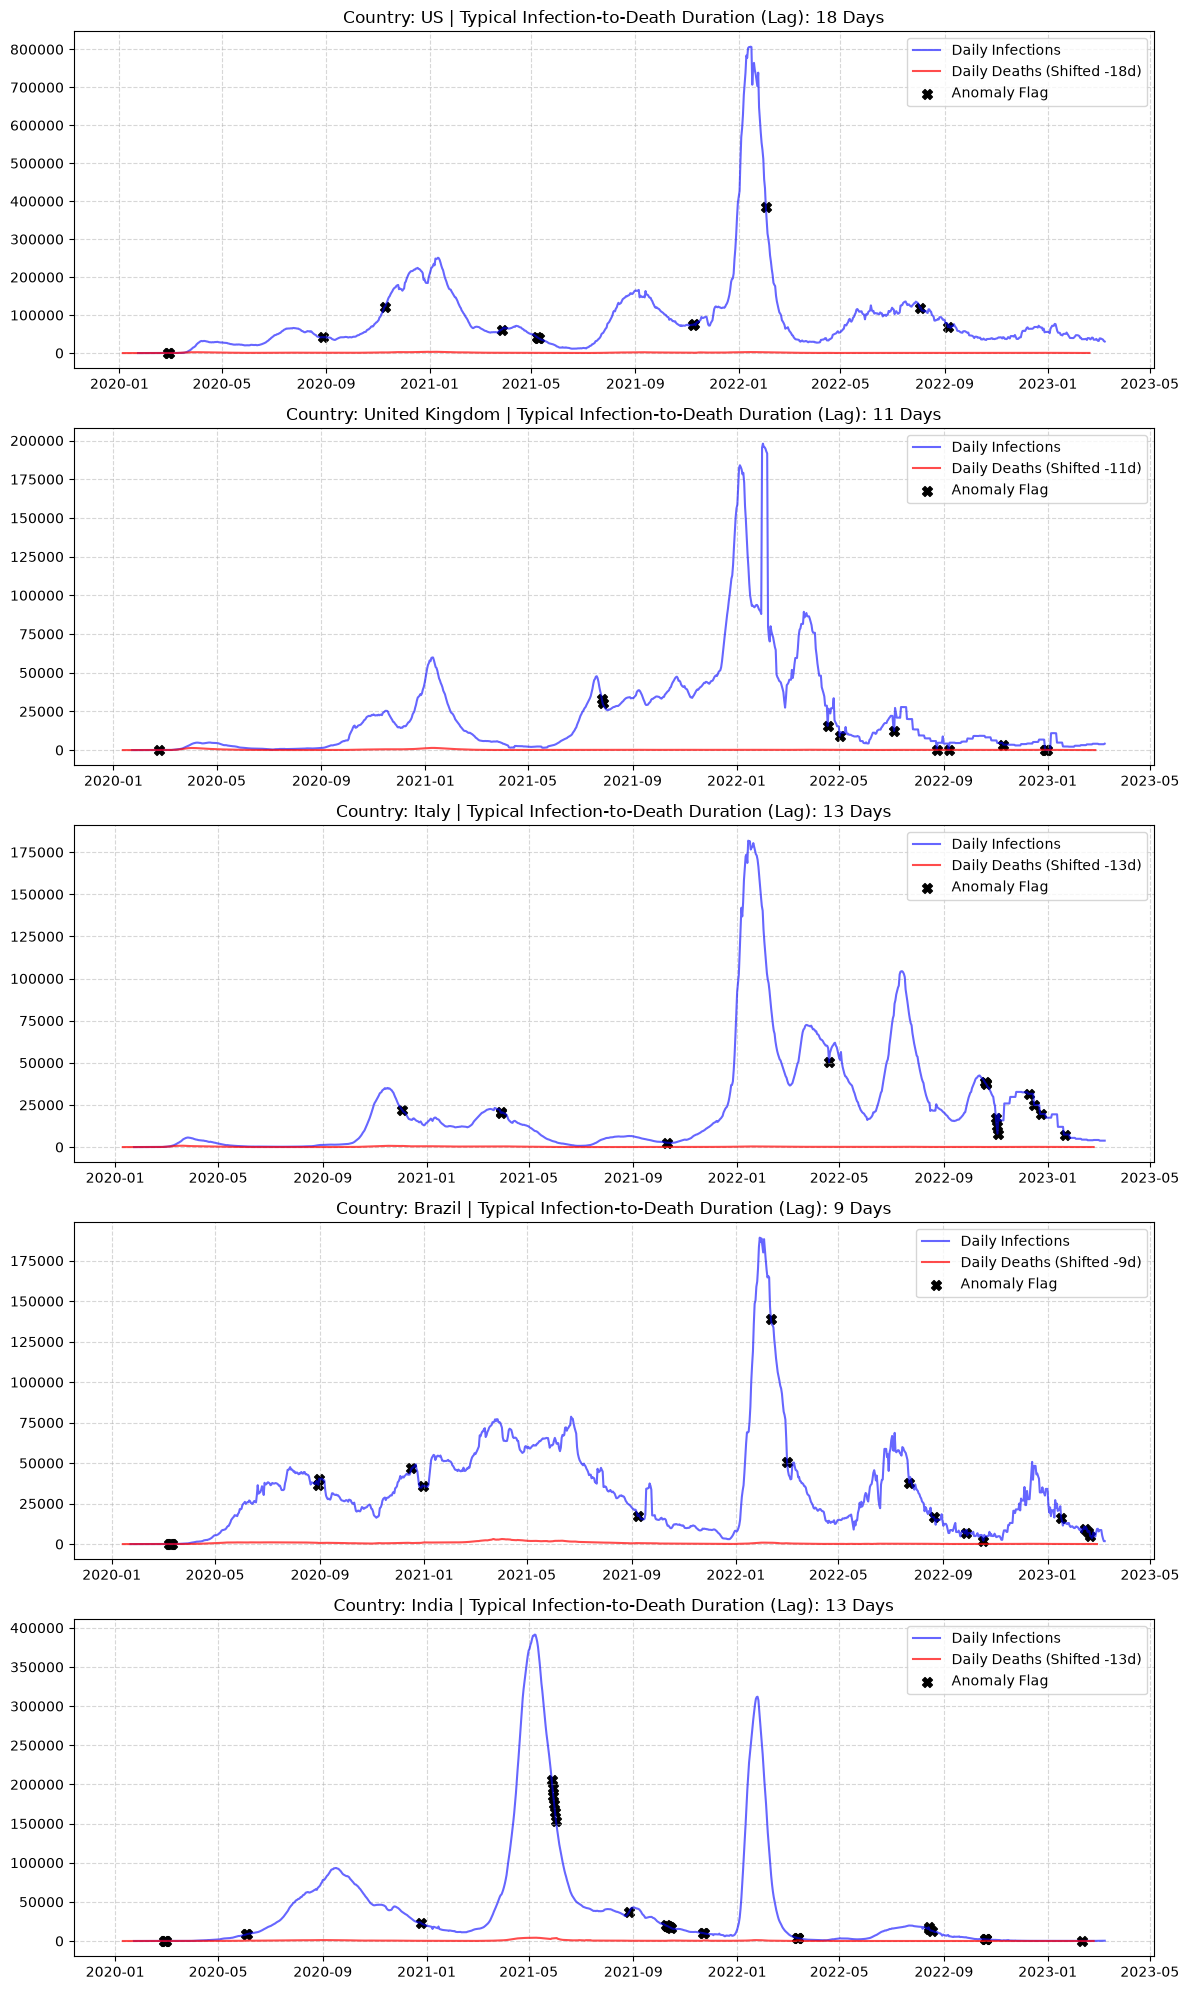

In [40]:
# Plotting Infection Rates vs Shifted Death Rates with Anomaly Highlights
fig, axes = plt.subplots(len(countries), 1, figsize=(12, 4 * len(countries)), sharex=False)

for i, country in enumerate(countries):
    ax = axes[i] if len(countries) > 1 else axes
    df = country_data[country]
    opt_lag = lag_results[country]['optimal_lag']
    
    # Plot daily infections
    ax.plot(df.index, df['daily_infected'], label='Daily Infections', color='blue', alpha=0.6)
    
    # Plot daily deaths shifted back by the optimal lag to align waves visually
    shifted_dates = df.index - pd.Timedelta(days=opt_lag)
    ax.plot(shifted_dates, df['daily_deaths'], label=f'Daily Deaths (Shifted -{opt_lag}d)', color='red', alpha=0.7)
    
    # Highlight anomalies if any
    anoms = anomaly_results[country]
    if not anoms.empty:
        ax.scatter(anoms.index, df.loc[anoms.index, 'daily_infected'], color='black', marker='X', s=50, label='Anomaly Flag')

    ax.set_title(f"Country: {country} | Typical Infection-to-Death Duration (Lag): {opt_lag} Days")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [41]:
# 1. Choose the estimated duration/lag of the disease in days
# (Medical studies often estimate about 14 to 21 days from symptom onset/infection to death)
disease_lag_days = 17

# 2. Create a copy of our data to work with
fatality_df = my_data[['smoothed_cases', 'smoothed_deaths']].copy()

# 3. Shift the smoothed cases backward by the disease lag
# This matches today's deaths with the cases that happened 17 days ago
fatality_df['lagged_cases'] = fatality_df['smoothed_cases'].shift(
    disease_lag_days
)

# 4. Calculate the Daily Fatality Rate (%)
# Formula: (Deaths on Day T / Cases from 17 days ago) * 100
fatality_df['fatality_rate_percent'] = (
    fatality_df['smoothed_deaths'] / fatality_df['lagged_cases']
) * 100

# Clean up any infinite values or NaNs caused by division or shifting
fatality_df = fatality_df.replace([float('inf'), float('-inf')], pd.NA).dropna()

print(fatality_df[['smoothed_deaths', 'lagged_cases', 'fatality_rate_percent']].tail(10))

            smoothed_deaths  lagged_cases fatality_rate_percent
2023-02-28       271.142857  36509.714286              0.742659
2023-03-01       288.142857  36573.000000              0.787857
2023-03-02       306.142857  36403.714286              0.840966
2023-03-03       371.142857  36790.000000              1.008815
2023-03-04       370.142857  37574.285714              0.985096
2023-03-05       370.000000  34549.857143              1.070916
2023-03-06       376.714286  39542.428571              0.952684
2023-03-07       376.714286  39299.285714              0.958578
2023-03-08       341.000000  39028.285714              0.873725
2023-03-09       316.571429  36016.285714              0.878967


In [42]:
# Calculate a 14-day rolling average for a smoother trend line
fatality_df['smooth_fatality_rate'] = (
    fatality_df['fatality_rate_percent'].rolling(window=14).mean()
)

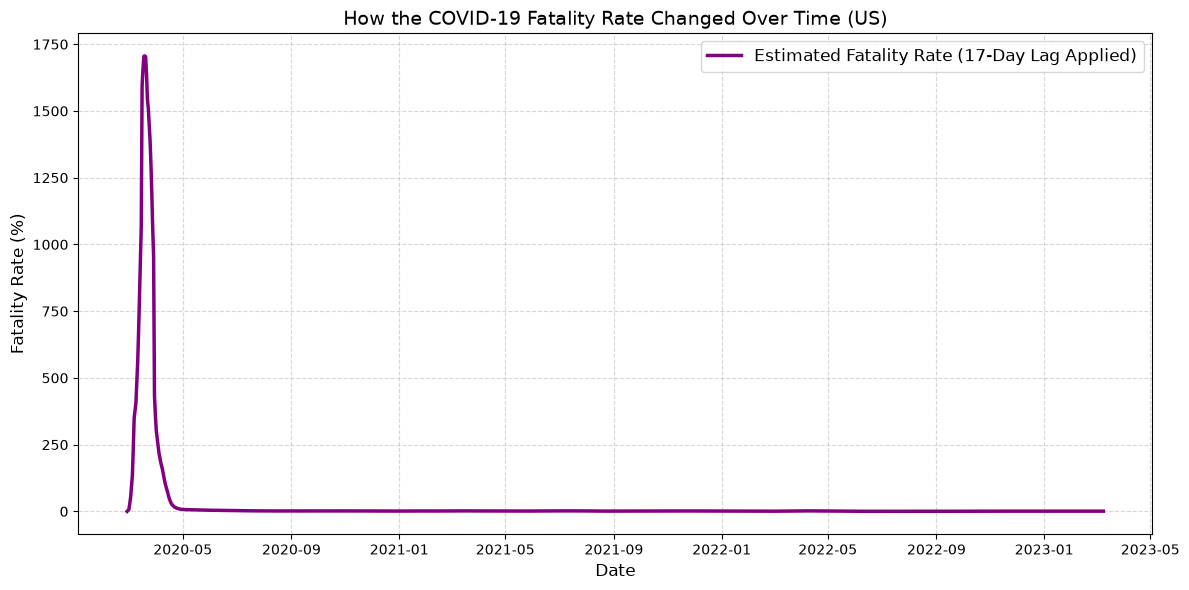

In [43]:
plt.figure(figsize=(12, 6))

# Plot the smoothed fatality rate percentage
plt.plot(
    fatality_df.index,
    fatality_df['smooth_fatality_rate'],
    color='purple',
    linewidth=2.5,
    label=f'Estimated Fatality Rate ({disease_lag_days}-Day Lag Applied)',
)

plt.title(
    f'How the COVID-19 Fatality Rate Changed Over Time ({country_name})',
    fontsize=14,
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Fatality Rate (%)', fontsize=12)

# Add a grid and legend
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)

plt.tight_layout()
plt.show()

#### Compare Total Cumulative Cases Across Multiple Countries

C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2751198696.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  country_cases.index = pd.to_datetime(country_cases.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2751198696.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  country_cases.index = pd.to_datetime(country_cases.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2751198696.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  country_cases.index = pd.to_datetime(country_cases.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\2751198696.py:

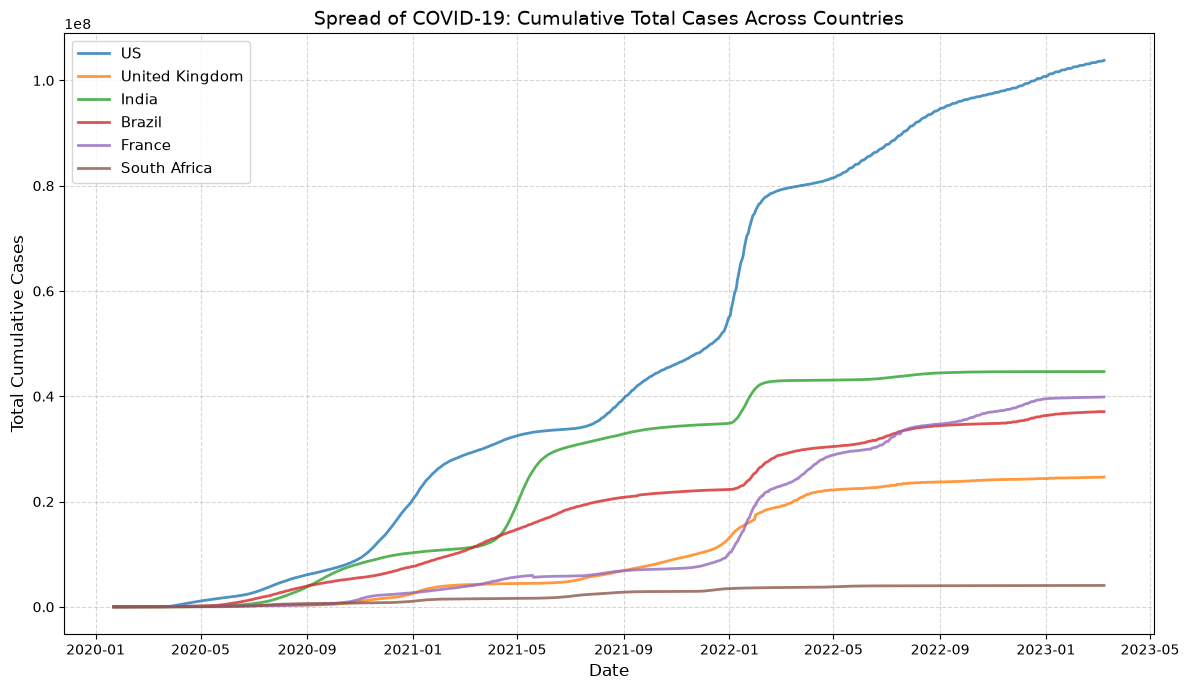

In [44]:
# 1. Choose a list of countries you want to compare
countries_to_compare = [
    'US',
    'United Kingdom',
    'India',
    'Brazil',
    'France',
    'South Africa',
]

# 2. Clean up the dataframe (remove Lat, Long, Province/State if present)
df_infected_clean = infected.drop(
    columns=['Lat', 'Long', 'Province/State'], errors='ignore'
)

# Set up the chart
plt.figure(figsize=(12, 7))

# 3. Loop through each country and plot its total cases over time
for country in countries_to_compare:
  if country in df_infected_clean.index:
    # Grab the total cases for this country
    country_cases = df_infected_clean.loc[country]

    # Convert index to dates
    country_cases.index = pd.to_datetime(country_cases.index)

    # Plot the line for this country
    plt.plot(
        country_cases.index, country_cases, label=country, linewidth=2, alpha=0.8
    )

# 4. Format the chart nicely
plt.title(
    'Spread of COVID-19: Cumulative Total Cases Across Countries', fontsize=14
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Cumulative Cases', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\1555625041.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  smooth_daily.index = pd.to_datetime(smooth_daily.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\1555625041.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  smooth_daily.index = pd.to_datetime(smooth_daily.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\1555625041.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  smooth_daily.index = pd.to_datetime(smooth_daily.index)
C:\Users\kkc29\AppData\Local\Temp\ipykernel_27300\1555625041.py:13: Us

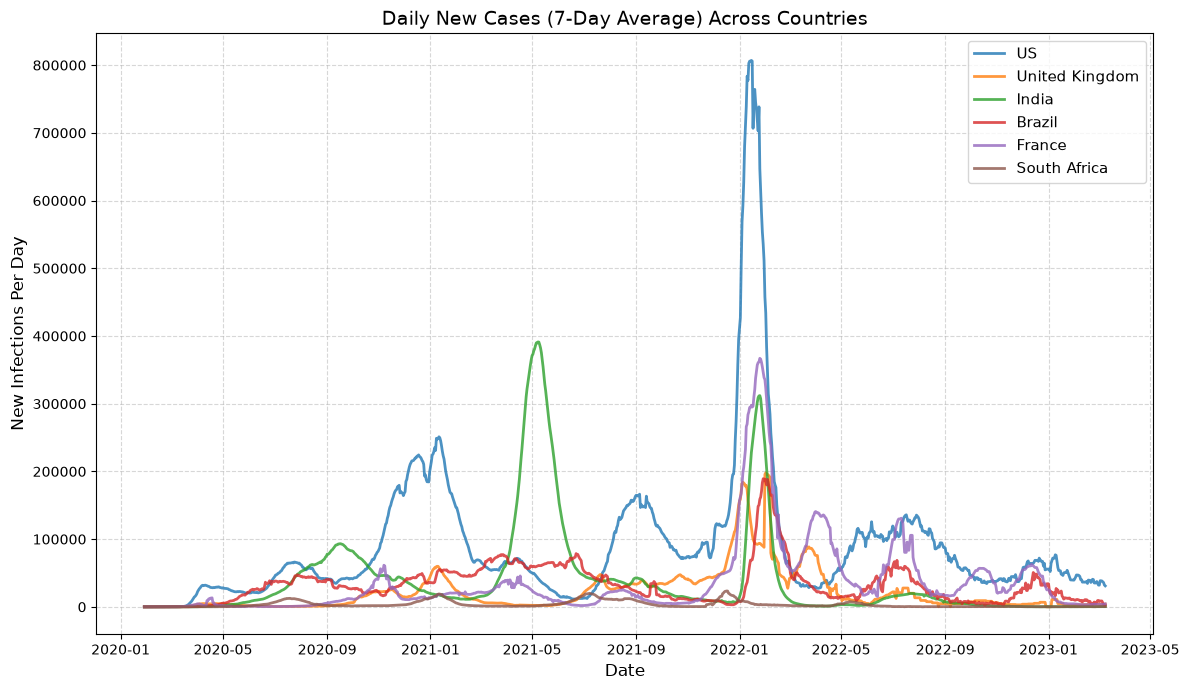

In [45]:
# Compare Daily Spread (The Waves) Side-by-Side
plt.figure(figsize=(12, 7))

for country in countries_to_compare:
  if country in df_infected_clean.index:
    # Get daily new cases by finding the difference between days
    daily_cases = df_infected_clean.loc[country].diff().clip(lower=0)

    # Smooth it out with a 7-day rolling average
    smooth_daily = daily_cases.rolling(window=7).mean()

    # Convert index to dates
    smooth_daily.index = pd.to_datetime(smooth_daily.index)

    plt.plot(
        smooth_daily.index,
        smooth_daily,
        label=country,
        linewidth=2,
        alpha=0.8,
    )

plt.title('Daily New Cases (7-Day Average) Across Countries', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('New Infections Per Day', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

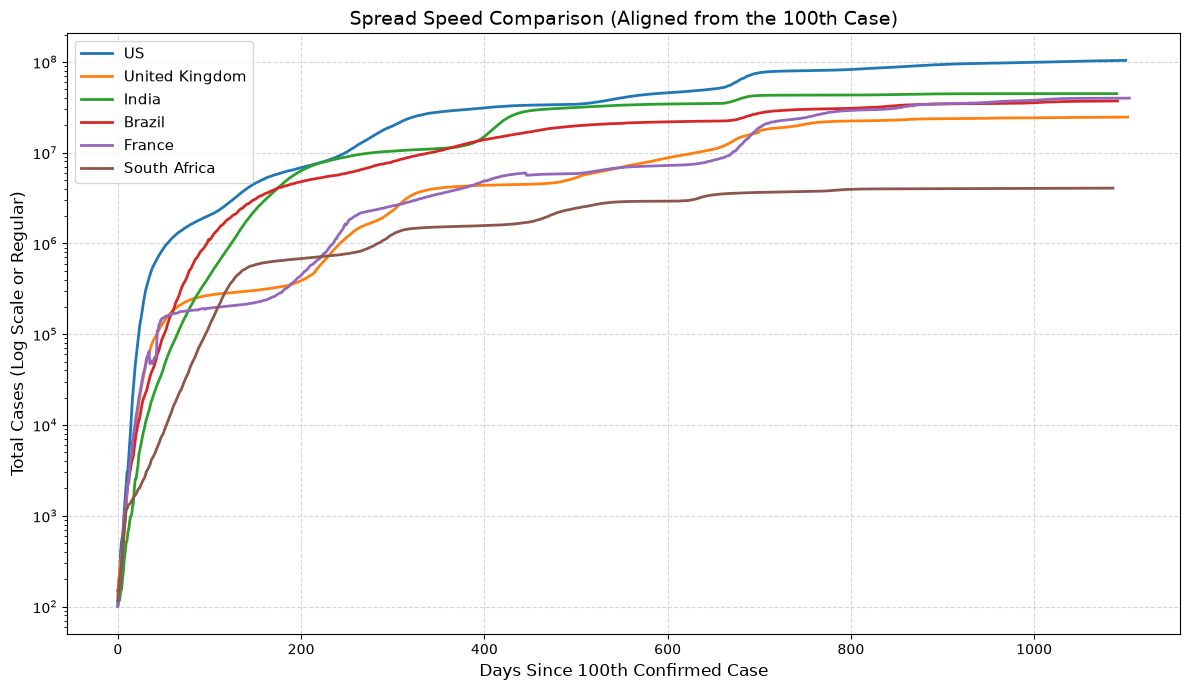

In [46]:
# Compare "Days Since the 100th Case" (The Alignment Trick)
plt.figure(figsize=(12, 7))

for country in countries_to_compare:
  if country in df_infected_clean.index:
    # Get total cases
    series = df_infected_clean.loc[country]

    # Keep only the days where total cases were 100 or more
    series_after_100 = series[series >= 100]

    if len(series_after_100) > 0:
      # Create a new timeline: Day 0, Day 1, Day 2... since the 100th case
      days_since_start = range(len(series_after_100))

      plt.plot(
          days_since_start,
          series_after_100.values,
          label=country,
          linewidth=2,
      )

plt.title('Spread Speed Comparison (Aligned from the 100th Case)', fontsize=14)
plt.xlabel('Days Since 100th Confirmed Case', fontsize=12)
plt.ylabel('Total Cases (Log Scale or Regular)', fontsize=12)

# Optional: Set y-axis to a logarithmic scale so exponential growth looks like a straight line
plt.yscale('log')

plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()